<a href="https://colab.research.google.com/github/srijansinha331-eng/Smart-City-Traffic-Flow-Simulator/blob/main/Smart_City_Traffic_Flow_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

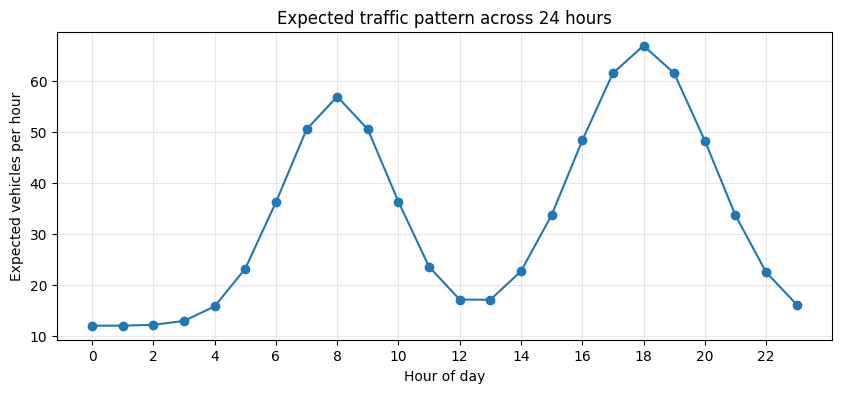

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

# Make the random results reproducible
np.random.seed(42)

DAYS = 30
JUNCTIONS = 10
HOURS = 24

# Typical traffic level for each hour of the day.
# Morning rush: around 8 AM; evening rush: around 6 PM.
hour = np.arange(HOURS)
morning_peak = 45 * np.exp(-0.5 * ((hour - 8) / 1.8) ** 2)
evening_peak = 55 * np.exp(-0.5 * ((hour - 18) / 2.2) ** 2)
daily_pattern = 12 + morning_peak + evening_peak

plt.figure(figsize=(10, 4))
plt.plot(hour, daily_pattern, marker="o")
plt.title("Expected traffic pattern across 24 hours")
plt.xlabel("Hour of day")
plt.ylabel("Expected vehicles per hour")
plt.xticks(range(0, 24, 2))
plt.grid(True, alpha=0.3)
plt.show()


In [2]:
# Give each junction a slightly different traffic level
junction_factors = np.linspace(0.75, 1.35, JUNCTIONS)

# Shape the expected traffic as (days, junctions, hours)
expected_traffic = (
    daily_pattern[None, None, :]
    * junction_factors[None, :, None]
)

# Small day-to-day variation
day_factors = np.random.uniform(0.90, 1.10, size=(DAYS, 1, 1))
expected_traffic = expected_traffic * day_factors

# Generate integer vehicle counts
traffic = np.random.poisson(lam=expected_traffic)

print("Traffic data shape (days, junctions, hours):", traffic.shape)
print("Total records:", traffic.size)
print("First day, first junction:", traffic[0, 0, :])


Traffic data shape (days, junctions, hours): (30, 10, 24)
Total records: 7200
First day, first junction: [ 7  6 12  7 15 20 31 34 50 34 24 20 18 15 20 25 32 56 47 39 31 30 22 10]


In [3]:
# Total vehicles for each junction across all 30 days and 24 hours
vehicles_by_junction = traffic.sum(axis=(0, 2))

# Total vehicles for each hour of the day, across all days and junctions
vehicles_by_hour = traffic.sum(axis=(0, 1))

# The busiest junction and busiest hour
busiest_junction = int(np.argmax(vehicles_by_junction))
peak_hour = int(np.argmax(vehicles_by_hour))

print("Total vehicles simulated:", int(traffic.sum()))
print("Busiest junction:", busiest_junction + 1)
print("Vehicles at busiest junction:", int(vehicles_by_junction[busiest_junction]))
print("Peak hour:", f"{peak_hour:02d}:00–{(peak_hour + 1) % 24:02d}:00")
print("Vehicles during peak hour (all junctions, all days):", int(vehicles_by_hour[peak_hour]))

print("\nVehicles by junction:")
for j, count in enumerate(vehicles_by_junction, start=1):
    print(f"Junction {j}: {int(count):,} vehicles")


Total vehicles simulated: 246578
Busiest junction: 10
Vehicles at busiest junction: 31552
Peak hour: 18:00–19:00
Vehicles during peak hour (all junctions, all days): 20930

Vehicles by junction:
Junction 1: 17,761 vehicles
Junction 2: 19,491 vehicles
Junction 3: 21,015 vehicles
Junction 4: 22,095 vehicles
Junction 5: 23,991 vehicles
Junction 6: 25,687 vehicles
Junction 7: 26,463 vehicles
Junction 8: 28,532 vehicles
Junction 9: 29,991 vehicles
Junction 10: 31,552 vehicles


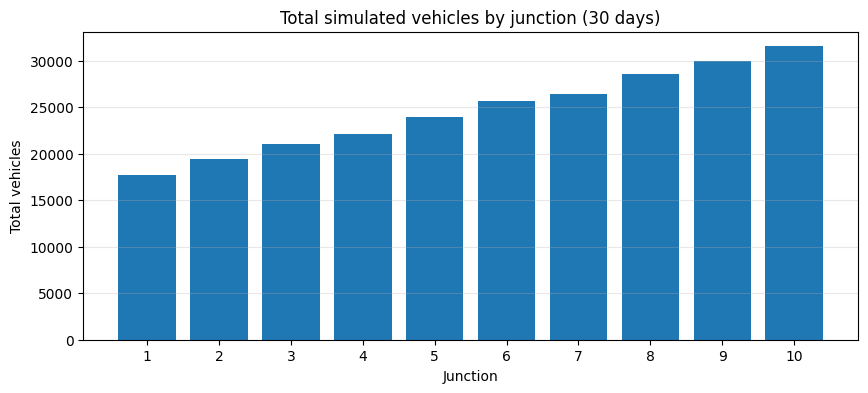

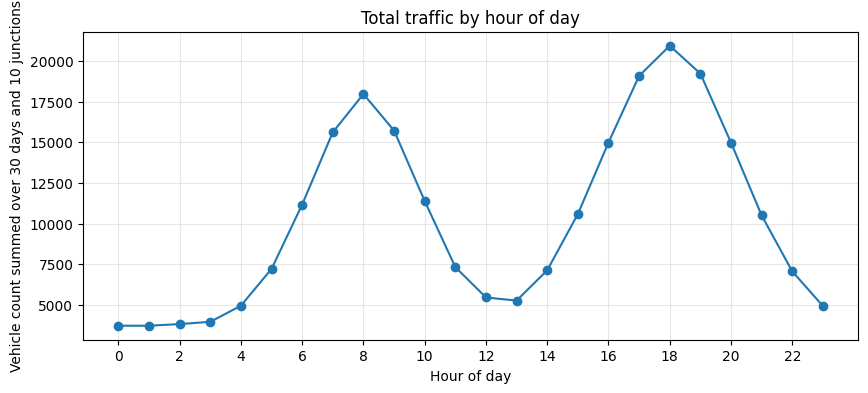

In [4]:
plt.figure(figsize=(10, 4))
plt.bar(np.arange(1, JUNCTIONS + 1), vehicles_by_junction)
plt.title("Total simulated vehicles by junction (30 days)")
plt.xlabel("Junction")
plt.ylabel("Total vehicles")
plt.xticks(np.arange(1, JUNCTIONS + 1))
plt.grid(axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(hour, vehicles_by_hour, marker="o")
plt.title("Total traffic by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Vehicle count summed over 30 days and 10 junctions")
plt.xticks(range(0, 24, 2))
plt.grid(True, alpha=0.3)
plt.show()


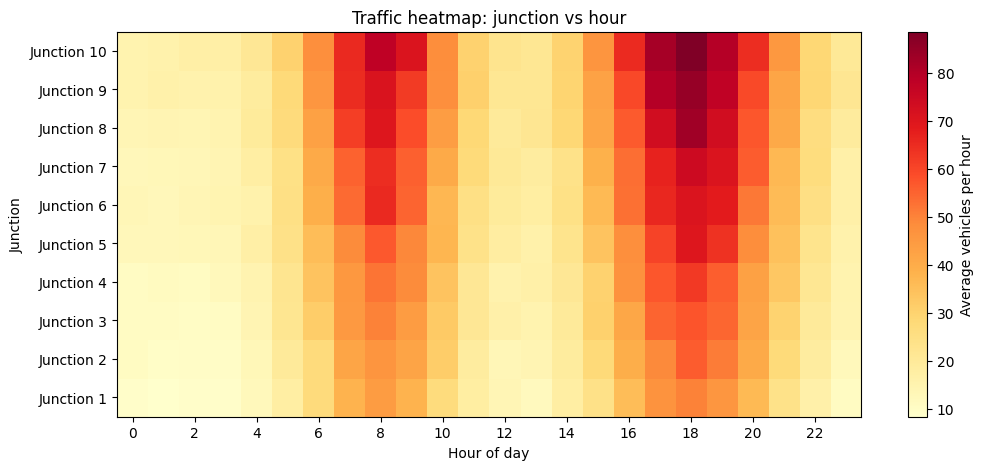

In [5]:
# Average across the 30 days -> shape is (junctions, hours)
average_traffic = traffic.mean(axis=0)

plt.figure(figsize=(12, 5))
plt.imshow(average_traffic, aspect="auto", origin="lower", cmap="YlOrRd")
plt.colorbar(label="Average vehicles per hour")
plt.title("Traffic heatmap: junction vs hour")
plt.xlabel("Hour of day")
plt.ylabel("Junction")
plt.xticks(range(0, 24, 2))
plt.yticks(range(JUNCTIONS), [f"Junction {j}" for j in range(1, JUNCTIONS + 1)])
plt.show()


In [6]:
# Loop version: add all counts using Python loops
def total_with_loops(data):
    total = 0
    for day in range(data.shape[0]):
        for junction in range(data.shape[1]):
            for h in range(data.shape[2]):
                total += int(data[day, junction, h])
    return total

# Vectorized version: NumPy performs the sum efficiently
def total_vectorized(data):
    return int(np.sum(data))

# Confirm both methods produce the same answer
assert total_with_loops(traffic) == total_vectorized(traffic)
print("Both methods return:", total_vectorized(traffic))

# %timeit is a notebook magic command; it works in Google Colab/Jupyter
%timeit total_with_loops(traffic)
%timeit total_vectorized(traffic)


Both methods return: 246578
1.18 ms ± 207 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
3.89 µs ± 58 ns per loop (mean ± std. dev. of 7 runs, 100000 loops each)


In [7]:
overall_average = traffic.mean()
junction_averages = traffic.mean(axis=(0, 2))

print(f"Overall average count per junction-hour: {overall_average:.2f}")
print("\nPossible high-traffic junctions:")
found = False
for j, avg in enumerate(junction_averages, start=1):
    if avg > overall_average:
        print(f"Junction {j}: average {avg:.2f} vehicles/hour")
        found = True

if not found:
    print("No junction was above the overall average.")

print("\nProject completed successfully!")


Overall average count per junction-hour: 34.25

Possible high-traffic junctions:
Junction 6: average 35.68 vehicles/hour
Junction 7: average 36.75 vehicles/hour
Junction 8: average 39.63 vehicles/hour
Junction 9: average 41.65 vehicles/hour
Junction 10: average 43.82 vehicles/hour

Project completed successfully!
